# RQ16 — Common-test sensitivity of redundancy and homology effects

## Scientific question

**How much of the apparent R/S generalization effect reflects a change in model behavior, and how much reflects the fact that different R/S conditions evaluate different proteins?**

The native factorial benchmark intentionally uses the frozen Stage-08 outer tests. Consequently,

\[
\Delta M_{\mathrm{native}}
=
M(R_2,S_2;\mathcal T_2)
-
M(R_1,S_1;\mathcal T_1)
\]

mixes:

- changes induced by the training/generalization regime;
- changes in which entities compose the outer test.

RQ16 is a **sensitivity analysis**, not a replacement benchmark. It recomputes metrics on exact-sequence intersections:

\[
\mathcal T_{\mathrm{common}}
=
\mathcal T_1\cap\mathcal T_2
\]

so that:

\[
\Delta M_{\mathrm{common}}
=
M(R_2,S_2;\mathcal T_{\mathrm{common}})
-
M(R_1,S_1;\mathcal T_{\mathrm{common}}).
\]

If native and common-test effects tell the same directional and quantitative story, the R/S conclusion is robust to test composition.


## Analysis hierarchy

### A. S sensitivity — primary common-test analysis

At fixed `task × R × representation × algorithm`:

- intersect outer-test exact sequences across S conditions;
- recompute MCC/AP-skill or MCC/macro-F1;
- compare native and common-test S deltas.

This is the cleanest common-test analysis because at fixed R the biological universe is unchanged while Stage-08 homology topology changes.

### B. R sensitivity — secondary

At fixed `task × S × representation × algorithm`:

- intersect exact sequences across R;
- recompute the same metrics.

This is a stricter sensitivity analysis because R changes the redundancy-controlled biological universe itself; common entities can therefore represent only a subset of the full R effect.

### C. Four-level intersections

For each fixed R, compute:

`S90 ∩ S70 ∩ S50 ∩ S30`

and analogously across all four R levels.

This gives a single common population on which the complete trajectory can be evaluated.

### D. Pairwise intersections

All six ordered contrasts:

`90→70`, `90→50`, `90→30`, `70→50`, `70→30`, `50→30`

are also recomputed using their pair-specific common entities. Pairwise intersections are expected to retain more support than four-level intersections.

### E. Four-corner R×S interaction sensitivity

For each `task × representation × algorithm`, intersect:

- R90/S90
- R90/S30
- R30/S90
- R30/S30

and recompute the extreme interaction on the exact same proteins:

\[
I =
[M(30,30)-M(90,30)]
-
[M(30,90)-M(90,90)].
\]

This directly audits the strongest RQ4 claim.


## Interpretation contract

- Native R/S effects remain the authoritative frozen-benchmark results.
- Common-test results quantify **sensitivity to test composition**.
- A common-test delta is paired at the entity level because both fitted models are evaluated on the same sequences.
- It does **not** isolate a pure causal “training effect”: the models were trained under different R/S conditions.
- Four-way/four-corner intersections can become biologically narrow; their retained support is always reported.
- Pairwise common tests are never forced to use a minimum arbitrary overlap fraction. Instead, overlap and class support are exposed explicitly.
- Binary metrics requiring both classes become `NA` if a common set loses a class.
- Multiclass common sets report the number of represented classes and minimum class support.
- VAL remains evidence-limited; common-test effects involving very few VAL positives must be interpreted with RQ10.
- MCC is the primary supervised metric.
- Binary AP is reported as prevalence-normalized AP skill.
- Multiclass uses macro-F1 as the main supporting metric.
- RQ17, not this notebook, provides bootstrap uncertainty.


In [1]:
from pathlib import Path
from functools import lru_cache
import hashlib
import itertools
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    recall_score,
    roc_auc_score,
    confusion_matrix,
)

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 500)
pd.set_option("display.width", 280)
pd.set_option("display.max_rows", 500)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

TASK_PATHS = {
    "global_easy": "global_easy",
    "global_hard": "global_hard",
    "global_mixed": "global_mixed",
    "subtype_endolysin": "subtype_binary/endolysin",
    "subtype_depolymerase": "subtype_binary/depolymerase",
    "subtype_val": "subtype_binary/virion_associated_lytic_enzyme",
    "multiclass_clean": "multiclass_clean",
}

BINARY_TASKS = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

MULTICLASS_TASKS = ["multiclass_clean"]

LEVEL_PAIRS = list(itertools.combinations([90, 70, 50, 30], 2))

BINARY_METRICS = [
    "mcc",
    "ap_skill",
    "roc_auc",
    "f1",
    "recall",
    "specificity",
    "balanced_accuracy",
]

MULTICLASS_METRICS = [
    "mcc",
    "macro_f1",
    "balanced_accuracy",
]

PRIMARY_SUPPORT_METRIC = {
    "binary": "ap_skill",
    "multiclass": "macro_f1",
}

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/training_supervised").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate the PhageLysClass project root containing "
        "results/analysis_supervised/stage12a and results/training_supervised."
    )

ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
TRAINING_ROOT = ROOT / "results/training_supervised"
CACHE_DIR = ROOT / "results/analysis_supervised/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("TRAINING_ROOT:", TRAINING_ROOT)
print("CACHE_DIR:", CACHE_DIR)


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
TRAINING_ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/training_supervised
CACHE_DIR: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache


# 1. Load and validate the frozen supervised benchmark


In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

required = {
    "task", "R", "S", "representation", "algorithm", "mcc",
}
missing = required - set(master.columns)
if missing:
    raise KeyError(f"Stage12A master missing columns: {sorted(missing)}")

TASKS = sorted(master["task"].unique())
REPS = sorted(master["representation"].unique())
ALGORITHMS = sorted(master["algorithm"].unique())

assert set(TASKS) == set(TASK_PATHS)

expected = len(TASKS) * 16 * len(REPS) * len(ALGORITHMS)
assert len(master) == expected, (len(master), expected)

coverage = (
    master.groupby(["task", "representation", "algorithm"])
    .size()
    .rename("n_RxS")
    .reset_index()
)

assert coverage["n_RxS"].eq(16).all()

print("Experiment families:", len(master))
print("Tasks:", TASKS)
print("Representations:", REPS)
print("Algorithms:", ALGORITHMS)
print("Expected surfaces:", len(TASKS) * len(REPS) * len(ALGORITHMS))


Experiment families: 2240
Tasks: ['global_easy', 'global_hard', 'global_mixed', 'multiclass_clean', 'subtype_depolymerase', 'subtype_endolysin', 'subtype_val']
Representations: ['esm2_t30_150m', 'esm2_t6_8m', 'onehot_1024', 'roxy_48']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']
Expected surfaces: 140


# 2. Prepare Stage12A AP-skill and task-type metadata


In [3]:
def detect_prevalence(df):
    for c in [
        "test_prevalence",
        "prevalence",
        "positive_prevalence",
        "class_prevalence",
    ]:
        if c in df.columns:
            return pd.to_numeric(df[c], errors="coerce"), c

    if {"n_positive", "n_test"} <= set(df.columns):
        return (
            pd.to_numeric(df["n_positive"], errors="coerce")
            / pd.to_numeric(df["n_test"], errors="coerce")
        ), "derived_from_n_positive_n_test"

    if {"tp", "fn", "tn", "fp"} <= set(df.columns):
        pos = (
            pd.to_numeric(df["tp"], errors="coerce")
            + pd.to_numeric(df["fn"], errors="coerce")
        )
        n = (
            pos
            + pd.to_numeric(df["tn"], errors="coerce")
            + pd.to_numeric(df["fp"], errors="coerce")
        )
        return pos / n, "derived_from_confusion_counts"

    return pd.Series(np.nan, index=df.index), None

master["task_type"] = np.where(
    master["task"].isin(BINARY_TASKS),
    "binary",
    "multiclass",
)

prevalence, prevalence_source = detect_prevalence(master)
master["prevalence_for_ap"] = prevalence

if "ap" in master.columns:
    denom = 1.0 - master["prevalence_for_ap"]
    master["ap_skill"] = np.where(
        denom > 0,
        (
            pd.to_numeric(master["ap"], errors="coerce")
            - master["prevalence_for_ap"]
        )
        / denom,
        np.nan,
    )

macro_f1_col = next(
    (
        c for c in ["macro_f1", "f1_macro"]
        if c in master.columns
    ),
    None,
)

if macro_f1_col is not None and macro_f1_col != "macro_f1":
    master["macro_f1"] = pd.to_numeric(
        master[macro_f1_col],
        errors="coerce",
    )

print("Prevalence source:", prevalence_source)
print("AP skill available:", "ap_skill" in master.columns)
print("Macro-F1 source:", macro_f1_col)


Prevalence source: prevalence
AP skill available: True
Macro-F1 source: macro_f1


# 3. Prediction identity and metric utilities


In [4]:
def experiment_dir(task, r, s, representation, algorithm):
    return (
        TRAINING_ROOT
        / TASK_PATHS[task]
        / f"R{r}_S{s}"
        / representation
        / algorithm
    )

def prediction_path(task, r, s, representation, algorithm):
    return (
        experiment_dir(task, r, s, representation, algorithm)
        / "outer_test_predictions.parquet"
    )

def _clean_text(series):
    return (
        series.astype("string")
        .fillna("")
        .str.strip()
        .astype(str)
    )

def attach_sequence_key(df):
    out = df.copy()

    for c in ["sequence_sha256", "sequence_uid", "entity_id"]:
        if c in out.columns:
            key = _clean_text(out[c])
            if key.ne("").all() and not key.duplicated().any():
                out["sequence_key"] = key.str.lower() if c == "sequence_sha256" else key
                out["sequence_key_source"] = c
                return out

    for c in ["sequence", "sequence_norm", "seq"]:
        if c in out.columns:
            seq = (
                _clean_text(out[c])
                .str.replace(r"\\s+", "", regex=True)
                .str.upper()
            )
            if seq.ne("").all():
                key = seq.map(
                    lambda x: hashlib.sha256(
                        x.encode("utf-8")
                    ).hexdigest()
                )
                if not key.duplicated().any():
                    out["sequence_key"] = key
                    out["sequence_key_source"] = "derived_sequence_sha256"
                    return out

    raise RuntimeError(
        "Could not construct a unique exact-sequence identity key. "
        f"Columns: {list(out.columns)}"
    )

def task_type(task):
    return "binary" if task in BINARY_TASKS else "multiclass"

def _binary_y(values):
    s = pd.Series(values)
    if pd.api.types.is_bool_dtype(s):
        return s.astype(int).to_numpy()

    numeric = pd.to_numeric(s, errors="coerce")
    if numeric.notna().all():
        uniq = set(numeric.astype(int).unique())
        if uniq <= {0, 1}:
            return numeric.astype(int).to_numpy()

    mapping = {
        "false": 0, "true": 1,
        "negative": 0, "positive": 1,
        "n": 0, "p": 1,
        "0": 0, "1": 1,
    }
    mapped = _clean_text(s).str.lower().map(mapping)
    if mapped.notna().all():
        return mapped.astype(int).to_numpy()

    raise ValueError(
        f"Could not normalize binary labels: {sorted(s.astype(str).unique())[:20]}"
    )

def metric_bundle(df, task):
    out = {
        "n": int(len(df)),
        "n_classes": np.nan,
        "min_class_count": np.nan,
        "n_positive": np.nan,
        "prevalence": np.nan,
    }

    if len(df) == 0:
        return out

    if "y_true" not in df.columns or "y_pred" not in df.columns:
        raise KeyError("Prediction file requires y_true and y_pred.")

    if task in BINARY_TASKS:
        y_true = _binary_y(df["y_true"])
        y_pred = _binary_y(df["y_pred"])

        counts = pd.Series(y_true).value_counts()
        out["n_classes"] = int(len(counts))
        out["min_class_count"] = int(counts.min()) if len(counts) else 0
        out["n_positive"] = int(np.sum(y_true == 1))
        out["prevalence"] = float(np.mean(y_true == 1))

        if len(counts) < 2:
            for m in BINARY_METRICS:
                out[m] = np.nan
            return out

        out["mcc"] = float(matthews_corrcoef(y_true, y_pred))
        out["f1"] = float(
            f1_score(y_true, y_pred, pos_label=1, zero_division=0)
        )
        out["recall"] = float(
            recall_score(y_true, y_pred, pos_label=1, zero_division=0)
        )
        out["balanced_accuracy"] = float(
            balanced_accuracy_score(y_true, y_pred)
        )

        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        out["specificity"] = float(
            tn / (tn + fp)
        ) if (tn + fp) else np.nan

        score_col = next(
            (
                c for c in [
                    "score_positive",
                    "score",
                    "probability",
                    "proba_positive",
                ]
                if c in df.columns
            ),
            None,
        )

        if score_col is not None:
            score = pd.to_numeric(
                df[score_col],
                errors="coerce",
            ).to_numpy(float)

            valid = np.isfinite(score)
            yt = y_true[valid]
            sc = score[valid]

            if len(np.unique(yt)) == 2:
                ap = float(average_precision_score(yt, sc))
                prev = float(np.mean(yt == 1))
                out["ap"] = ap
                out["ap_skill"] = (
                    (ap - prev) / (1.0 - prev)
                    if prev < 1.0
                    else np.nan
                )
                out["roc_auc"] = float(
                    roc_auc_score(yt, sc)
                )
            else:
                out["ap"] = np.nan
                out["ap_skill"] = np.nan
                out["roc_auc"] = np.nan
        else:
            out["ap"] = np.nan
            out["ap_skill"] = np.nan
            out["roc_auc"] = np.nan

    else:
        y_true = df["y_true"].astype(str).to_numpy()
        y_pred = df["y_pred"].astype(str).to_numpy()

        counts = pd.Series(y_true).value_counts()
        out["n_classes"] = int(len(counts))
        out["min_class_count"] = int(counts.min()) if len(counts) else 0

        if len(counts) < 2:
            for m in MULTICLASS_METRICS:
                out[m] = np.nan
            return out

        labels = sorted(pd.Series(y_true).unique())

        out["mcc"] = float(
            matthews_corrcoef(y_true, y_pred)
        )
        out["macro_f1"] = float(
            f1_score(
                y_true,
                y_pred,
                labels=labels,
                average="macro",
                zero_division=0,
            )
        )
        out["balanced_accuracy"] = float(
            balanced_accuracy_score(y_true, y_pred)
        )

    return out

@lru_cache(maxsize=64)
def load_prediction(task, r, s, representation, algorithm):
    p = prediction_path(task, r, s, representation, algorithm)
    if not p.is_file():
        raise FileNotFoundError(p)

    df = pd.read_parquet(p)
    df = attach_sequence_key(df)

    required = {"sequence_key", "y_true", "y_pred"}
    missing = required - set(df.columns)
    if missing:
        raise KeyError(f"{p}: missing {sorted(missing)}")

    if df["sequence_key"].duplicated().any():
        raise RuntimeError(f"{p}: duplicate sequence identities.")

    return df


# 4. Recompute native metrics from prediction files and QC against Stage12A


In [5]:
native_rows = []
identity_rows = []

for row in master.itertuples(index=False):
    pred = load_prediction(
        row.task,
        int(row.R),
        int(row.S),
        row.representation,
        row.algorithm,
    )

    mb = metric_bundle(pred, row.task)

    native_rows.append({
        "task": row.task,
        "R": int(row.R),
        "S": int(row.S),
        "representation": row.representation,
        "algorithm": row.algorithm,
        "task_type": task_type(row.task),
        **mb,
    })

    identity_rows.append({
        "task": row.task,
        "R": int(row.R),
        "S": int(row.S),
        "representation": row.representation,
        "algorithm": row.algorithm,
        "sequence_key_source": pred["sequence_key_source"].iloc[0],
        "n_prediction_rows": len(pred),
    })

native_recalc = pd.DataFrame(native_rows)
identity_audit = pd.DataFrame(identity_rows)

assert len(native_recalc) == len(master)

qc = master.merge(
    native_recalc,
    on=[
        "task", "R", "S",
        "representation", "algorithm",
    ],
    how="left",
    suffixes=("_master", "_recalc"),
    validate="one_to_one",
)

qc["mcc_abs_diff"] = (
    pd.to_numeric(qc["mcc_master"], errors="coerce")
    - pd.to_numeric(qc["mcc_recalc"], errors="coerce")
).abs()

if "ap_skill_master" in qc.columns and "ap_skill_recalc" in qc.columns:
    qc["ap_skill_abs_diff"] = (
        pd.to_numeric(qc["ap_skill_master"], errors="coerce")
        - pd.to_numeric(qc["ap_skill_recalc"], errors="coerce")
    ).abs()

if "macro_f1_master" in qc.columns and "macro_f1_recalc" in qc.columns:
    qc["macro_f1_abs_diff"] = (
        pd.to_numeric(qc["macro_f1_master"], errors="coerce")
        - pd.to_numeric(qc["macro_f1_recalc"], errors="coerce")
    ).abs()

qc_cols = [
    c for c in [
        "mcc_abs_diff",
        "ap_skill_abs_diff",
        "macro_f1_abs_diff",
    ]
    if c in qc.columns
]

display(qc[qc_cols].describe())

assert qc["mcc_abs_diff"].max() < 1e-6

if "ap_skill_abs_diff" in qc.columns:
    assert qc.loc[
        qc["task"].isin(BINARY_TASKS),
        "ap_skill_abs_diff",
    ].dropna().max() < 1e-6

if "macro_f1_abs_diff" in qc.columns:
    assert qc.loc[
        qc["task"].isin(MULTICLASS_TASKS),
        "macro_f1_abs_diff",
    ].dropna().max() < 1e-6

print("QC metric columns used:", qc_cols)
print("PASS — prediction-derived native metrics reproduce Stage12A.")
display(identity_audit["sequence_key_source"].value_counts())


,mcc_abs_diff,ap_skill_abs_diff,macro_f1_abs_diff
count,2.240000e+03,1.920000e+03,3.200000e+02
mean,1.283076e-17,6.576499e-17,1.734723e-19
std,3.207073e-17,1.089749e-16,3.103168e-18
min,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00,0.000000e+00
50%,0.000000e+00,0.000000e+00,0.000000e+00
75%,0.000000e+00,1.110223e-16,0.000000e+00
max,1.110223e-16,4.440892e-16,5.551115e-17


QC metric columns used: ['mcc_abs_diff', 'ap_skill_abs_diff', 'macro_f1_abs_diff']
PASS — prediction-derived native metrics reproduce Stage12A.


sequence_key_source
sequence_uid    2240
Name: count, dtype: int64

The common-test calculations below use the same metric implementation that just reproduced the frozen Stage12A results.

Therefore, any native-versus-common difference is attributable to the evaluated entity set, not to a change in metric implementation.


# 5. Helper functions for exact common-test evaluation


In [6]:
native_lookup = {
    (
        row.task,
        int(row.R),
        int(row.S),
        row.representation,
        row.algorithm,
    ): row._asdict()
    for row in native_recalc.itertuples(index=False)
}

def intersect_predictions(frames):
    if not frames:
        return set()

    shared = set(frames[0]["sequence_key"].astype(str))
    for df in frames[1:]:
        shared &= set(df["sequence_key"].astype(str))
    return shared

def subset_on_ids(df, ids):
    return (
        df[df["sequence_key"].astype(str).isin(ids)]
        .copy()
        .sort_values("sequence_key")
        .reset_index(drop=True)
    )

def assert_shared_labels(subsets, context=""):
    if len(subsets) < 2 or len(subsets[0]) == 0:
        return

    ref = (
        subsets[0][["sequence_key", "y_true"]]
        .copy()
        .sort_values("sequence_key")
        .reset_index(drop=True)
    )

    for other in subsets[1:]:
        x = (
            other[["sequence_key", "y_true"]]
            .copy()
            .sort_values("sequence_key")
            .reset_index(drop=True)
        )

        if not ref["sequence_key"].equals(x["sequence_key"]):
            raise RuntimeError(
                f"{context}: common-test identity alignment failed."
            )

        a = ref["y_true"].to_numpy()
        b = x["y_true"].to_numpy()

        if not np.all(a == b):
            raise RuntimeError(
                f"{context}: y_true differs for the same exact sequence across conditions."
            )

def metrics_for_task(task):
    return BINARY_METRICS if task in BINARY_TASKS else MULTICLASS_METRICS

def sign_class(x, atol=1e-12):
    if pd.isna(x):
        return "NA"
    if x > atol:
        return "positive"
    if x < -atol:
        return "negative"
    return "zero"

def contrast_record(
    *,
    task,
    representation,
    algorithm,
    axis,
    fixed_level,
    level_A,
    level_B,
    native_A,
    native_B,
    common_A,
    common_B,
    overlap_meta,
):
    rows = []

    for metric in metrics_for_task(task):
        na = native_A.get(metric, np.nan)
        nb = native_B.get(metric, np.nan)
        ca = common_A.get(metric, np.nan)
        cb = common_B.get(metric, np.nan)

        native_delta = (
            nb - na
            if pd.notna(na) and pd.notna(nb)
            else np.nan
        )
        common_delta = (
            cb - ca
            if pd.notna(ca) and pd.notna(cb)
            else np.nan
        )

        rows.append({
            "task": task,
            "task_type": task_type(task),
            "representation": representation,
            "algorithm": algorithm,
            "axis": axis,
            "fixed_level": int(fixed_level),
            "level_A": int(level_A),
            "level_B": int(level_B),
            "contrast": f"{level_A}→{level_B}",
            "metric": metric,
            "native_A": na,
            "native_B": nb,
            "native_delta": native_delta,
            "common_A": ca,
            "common_B": cb,
            "common_delta": common_delta,
            "native_minus_common_delta": (
                native_delta - common_delta
                if pd.notna(native_delta) and pd.notna(common_delta)
                else np.nan
            ),
            "native_abs_effect": (
                abs(native_delta)
                if pd.notna(native_delta)
                else np.nan
            ),
            "common_abs_effect": (
                abs(common_delta)
                if pd.notna(common_delta)
                else np.nan
            ),
            "magnitude_ratio_common_over_native": (
                abs(common_delta) / abs(native_delta)
                if pd.notna(common_delta)
                and pd.notna(native_delta)
                and abs(native_delta) > 1e-12
                else np.nan
            ),
            "native_sign": sign_class(native_delta),
            "common_sign": sign_class(common_delta),
            "sign_agreement": (
                sign_class(native_delta) == sign_class(common_delta)
                if pd.notna(native_delta) and pd.notna(common_delta)
                else np.nan
            ),
            **overlap_meta,
        })

    return rows


# 6. Build pairwise, four-level, and four-corner common-test tables


In [7]:
pairwise_rows = []
fourway_metric_rows = []
fourway_contrast_rows = []
corner_metric_rows = []
corner_summary_rows = []
overlap_rows = []

surface_counter = 0

for task in TASKS:
    for rep in REPS:
        for alg in ALGORITHMS:
            surface_counter += 1

            preds = {}
            for r in R_LEVELS:
                for s in S_LEVELS:
                    preds[(r, s)] = load_prediction(
                        task, r, s, rep, alg
                    )

            # ------------------------------------------------------------
            # A. Pairwise S contrasts at fixed R
            # ------------------------------------------------------------
            for r in R_LEVELS:
                for s_a, s_b in LEVEL_PAIRS:
                    a = preds[(r, s_a)]
                    b = preds[(r, s_b)]

                    ids = intersect_predictions([a, b])
                    a_c = subset_on_ids(a, ids)
                    b_c = subset_on_ids(b, ids)

                    assert_shared_labels(
                        [a_c, b_c],
                        context=(
                            f"{task}/{rep}/{alg}/R{r}/"
                            f"S{s_a}-S{s_b}"
                        ),
                    )

                    ma = metric_bundle(a_c, task)
                    mb = metric_bundle(b_c, task)

                    overlap = {
                        "n_test_A": len(a),
                        "n_test_B": len(b),
                        "n_common": len(ids),
                        "common_fraction_of_A": (
                            len(ids) / len(a) if len(a) else np.nan
                        ),
                        "common_fraction_of_B": (
                            len(ids) / len(b) if len(b) else np.nan
                        ),
                        "common_fraction_of_smaller_test": (
                            len(ids) / min(len(a), len(b))
                            if min(len(a), len(b)) else np.nan
                        ),
                        "n_classes_common": ma["n_classes"],
                        "min_class_count_common": ma["min_class_count"],
                        "n_positive_common": ma["n_positive"],
                    }

                    pairwise_rows.extend(
                        contrast_record(
                            task=task,
                            representation=rep,
                            algorithm=alg,
                            axis="S",
                            fixed_level=r,
                            level_A=s_a,
                            level_B=s_b,
                            native_A=native_lookup[
                                (task, r, s_a, rep, alg)
                            ],
                            native_B=native_lookup[
                                (task, r, s_b, rep, alg)
                            ],
                            common_A=ma,
                            common_B=mb,
                            overlap_meta=overlap,
                        )
                    )

                    overlap_rows.append({
                        "task": task,
                        "representation": rep,
                        "algorithm": alg,
                        "intersection_type": "pairwise",
                        "axis": "S",
                        "fixed_level": r,
                        "levels": f"{s_a},{s_b}",
                        **overlap,
                    })

            # ------------------------------------------------------------
            # B. Pairwise R contrasts at fixed S
            # ------------------------------------------------------------
            for s in S_LEVELS:
                for r_a, r_b in LEVEL_PAIRS:
                    a = preds[(r_a, s)]
                    b = preds[(r_b, s)]

                    ids = intersect_predictions([a, b])
                    a_c = subset_on_ids(a, ids)
                    b_c = subset_on_ids(b, ids)

                    assert_shared_labels(
                        [a_c, b_c],
                        context=(
                            f"{task}/{rep}/{alg}/S{s}/"
                            f"R{r_a}-R{r_b}"
                        ),
                    )

                    ma = metric_bundle(a_c, task)
                    mb = metric_bundle(b_c, task)

                    overlap = {
                        "n_test_A": len(a),
                        "n_test_B": len(b),
                        "n_common": len(ids),
                        "common_fraction_of_A": (
                            len(ids) / len(a) if len(a) else np.nan
                        ),
                        "common_fraction_of_B": (
                            len(ids) / len(b) if len(b) else np.nan
                        ),
                        "common_fraction_of_smaller_test": (
                            len(ids) / min(len(a), len(b))
                            if min(len(a), len(b)) else np.nan
                        ),
                        "n_classes_common": ma["n_classes"],
                        "min_class_count_common": ma["min_class_count"],
                        "n_positive_common": ma["n_positive"],
                    }

                    pairwise_rows.extend(
                        contrast_record(
                            task=task,
                            representation=rep,
                            algorithm=alg,
                            axis="R",
                            fixed_level=s,
                            level_A=r_a,
                            level_B=r_b,
                            native_A=native_lookup[
                                (task, r_a, s, rep, alg)
                            ],
                            native_B=native_lookup[
                                (task, r_b, s, rep, alg)
                            ],
                            common_A=ma,
                            common_B=mb,
                            overlap_meta=overlap,
                        )
                    )

                    overlap_rows.append({
                        "task": task,
                        "representation": rep,
                        "algorithm": alg,
                        "intersection_type": "pairwise",
                        "axis": "R",
                        "fixed_level": s,
                        "levels": f"{r_a},{r_b}",
                        **overlap,
                    })

            # ------------------------------------------------------------
            # C. Four-S intersection at each fixed R
            # ------------------------------------------------------------
            for r in R_LEVELS:
                frames = [preds[(r, s)] for s in S_LEVELS]
                ids = intersect_predictions(frames)
                subsets = [subset_on_ids(x, ids) for x in frames]

                assert_shared_labels(
                    subsets,
                    context=f"{task}/{rep}/{alg}/R{r}/all-S",
                )

                per_level = {}
                for s, sub in zip(S_LEVELS, subsets):
                    mb = metric_bundle(sub, task)
                    per_level[s] = mb

                    for metric in metrics_for_task(task):
                        fourway_metric_rows.append({
                            "task": task,
                            "task_type": task_type(task),
                            "representation": rep,
                            "algorithm": alg,
                            "axis": "S",
                            "fixed_level": r,
                            "level": s,
                            "metric": metric,
                            "common_value": mb.get(metric, np.nan),
                            "n_common": len(ids),
                            "common_fraction_of_smallest_test": (
                                len(ids)
                                / min(len(x) for x in frames)
                                if min(len(x) for x in frames)
                                else np.nan
                            ),
                            "n_classes_common": mb["n_classes"],
                            "min_class_count_common": mb["min_class_count"],
                            "n_positive_common": mb["n_positive"],
                        })

                for s_a, s_b in LEVEL_PAIRS:
                    for metric in metrics_for_task(task):
                        ca = per_level[s_a].get(metric, np.nan)
                        cb = per_level[s_b].get(metric, np.nan)

                        na = native_lookup[
                            (task, r, s_a, rep, alg)
                        ].get(metric, np.nan)
                        nb = native_lookup[
                            (task, r, s_b, rep, alg)
                        ].get(metric, np.nan)

                        fourway_contrast_rows.append({
                            "task": task,
                            "task_type": task_type(task),
                            "representation": rep,
                            "algorithm": alg,
                            "axis": "S",
                            "fixed_level": r,
                            "level_A": s_a,
                            "level_B": s_b,
                            "contrast": f"{s_a}→{s_b}",
                            "metric": metric,
                            "native_delta": (
                                nb - na
                                if pd.notna(na) and pd.notna(nb)
                                else np.nan
                            ),
                            "common_delta": (
                                cb - ca
                                if pd.notna(ca) and pd.notna(cb)
                                else np.nan
                            ),
                            "n_common": len(ids),
                            "common_fraction_of_smallest_test": (
                                len(ids)
                                / min(len(x) for x in frames)
                                if min(len(x) for x in frames)
                                else np.nan
                            ),
                            "n_classes_common": per_level[s_a]["n_classes"],
                            "min_class_count_common": per_level[s_a]["min_class_count"],
                            "n_positive_common": per_level[s_a]["n_positive"],
                        })

                overlap_rows.append({
                    "task": task,
                    "representation": rep,
                    "algorithm": alg,
                    "intersection_type": "four_level",
                    "axis": "S",
                    "fixed_level": r,
                    "levels": "90,70,50,30",
                    "n_test_A": np.nan,
                    "n_test_B": np.nan,
                    "n_common": len(ids),
                    "common_fraction_of_A": np.nan,
                    "common_fraction_of_B": np.nan,
                    "common_fraction_of_smaller_test": (
                        len(ids)
                        / min(len(x) for x in frames)
                        if min(len(x) for x in frames)
                        else np.nan
                    ),
                    "n_classes_common": per_level[90]["n_classes"],
                    "min_class_count_common": per_level[90]["min_class_count"],
                    "n_positive_common": per_level[90]["n_positive"],
                })

            # ------------------------------------------------------------
            # D. Four-R intersection at each fixed S
            # ------------------------------------------------------------
            for s in S_LEVELS:
                frames = [preds[(r, s)] for r in R_LEVELS]
                ids = intersect_predictions(frames)
                subsets = [subset_on_ids(x, ids) for x in frames]

                assert_shared_labels(
                    subsets,
                    context=f"{task}/{rep}/{alg}/S{s}/all-R",
                )

                per_level = {}
                for r, sub in zip(R_LEVELS, subsets):
                    mb = metric_bundle(sub, task)
                    per_level[r] = mb

                    for metric in metrics_for_task(task):
                        fourway_metric_rows.append({
                            "task": task,
                            "task_type": task_type(task),
                            "representation": rep,
                            "algorithm": alg,
                            "axis": "R",
                            "fixed_level": s,
                            "level": r,
                            "metric": metric,
                            "common_value": mb.get(metric, np.nan),
                            "n_common": len(ids),
                            "common_fraction_of_smallest_test": (
                                len(ids)
                                / min(len(x) for x in frames)
                                if min(len(x) for x in frames)
                                else np.nan
                            ),
                            "n_classes_common": mb["n_classes"],
                            "min_class_count_common": mb["min_class_count"],
                            "n_positive_common": mb["n_positive"],
                        })

                for r_a, r_b in LEVEL_PAIRS:
                    for metric in metrics_for_task(task):
                        ca = per_level[r_a].get(metric, np.nan)
                        cb = per_level[r_b].get(metric, np.nan)

                        na = native_lookup[
                            (task, r_a, s, rep, alg)
                        ].get(metric, np.nan)
                        nb = native_lookup[
                            (task, r_b, s, rep, alg)
                        ].get(metric, np.nan)

                        fourway_contrast_rows.append({
                            "task": task,
                            "task_type": task_type(task),
                            "representation": rep,
                            "algorithm": alg,
                            "axis": "R",
                            "fixed_level": s,
                            "level_A": r_a,
                            "level_B": r_b,
                            "contrast": f"{r_a}→{r_b}",
                            "metric": metric,
                            "native_delta": (
                                nb - na
                                if pd.notna(na) and pd.notna(nb)
                                else np.nan
                            ),
                            "common_delta": (
                                cb - ca
                                if pd.notna(ca) and pd.notna(cb)
                                else np.nan
                            ),
                            "n_common": len(ids),
                            "common_fraction_of_smallest_test": (
                                len(ids)
                                / min(len(x) for x in frames)
                                if min(len(x) for x in frames)
                                else np.nan
                            ),
                            "n_classes_common": per_level[r_a]["n_classes"],
                            "min_class_count_common": per_level[r_a]["min_class_count"],
                            "n_positive_common": per_level[r_a]["n_positive"],
                        })

                overlap_rows.append({
                    "task": task,
                    "representation": rep,
                    "algorithm": alg,
                    "intersection_type": "four_level",
                    "axis": "R",
                    "fixed_level": s,
                    "levels": "90,70,50,30",
                    "n_test_A": np.nan,
                    "n_test_B": np.nan,
                    "n_common": len(ids),
                    "common_fraction_of_A": np.nan,
                    "common_fraction_of_B": np.nan,
                    "common_fraction_of_smaller_test": (
                        len(ids)
                        / min(len(x) for x in frames)
                        if min(len(x) for x in frames)
                        else np.nan
                    ),
                    "n_classes_common": per_level[90]["n_classes"],
                    "min_class_count_common": per_level[90]["min_class_count"],
                    "n_positive_common": per_level[90]["n_positive"],
                })

            # ------------------------------------------------------------
            # E. Four-corner common set for extreme R×S interaction
            # ------------------------------------------------------------
            corners = {
                "R90_S90": preds[(90, 90)],
                "R90_S30": preds[(90, 30)],
                "R30_S90": preds[(30, 90)],
                "R30_S30": preds[(30, 30)],
            }

            ids = intersect_predictions(list(corners.values()))
            corner_subsets = {
                name: subset_on_ids(df, ids)
                for name, df in corners.items()
            }

            assert_shared_labels(
                list(corner_subsets.values()),
                context=f"{task}/{rep}/{alg}/four-corner",
            )

            corner_metrics = {
                name: metric_bundle(df, task)
                for name, df in corner_subsets.items()
            }

            for name, mb in corner_metrics.items():
                for metric in metrics_for_task(task):
                    corner_metric_rows.append({
                        "task": task,
                        "task_type": task_type(task),
                        "representation": rep,
                        "algorithm": alg,
                        "corner": name,
                        "metric": metric,
                        "common_value": mb.get(metric, np.nan),
                        "n_common": len(ids),
                        "common_fraction_of_smallest_corner_test": (
                            len(ids)
                            / min(len(x) for x in corners.values())
                            if min(len(x) for x in corners.values())
                            else np.nan
                        ),
                        "n_classes_common": mb["n_classes"],
                        "min_class_count_common": mb["min_class_count"],
                        "n_positive_common": mb["n_positive"],
                    })

            for metric in metrics_for_task(task):
                n_9090 = native_lookup[
                    (task, 90, 90, rep, alg)
                ].get(metric, np.nan)
                n_9030 = native_lookup[
                    (task, 90, 30, rep, alg)
                ].get(metric, np.nan)
                n_3090 = native_lookup[
                    (task, 30, 90, rep, alg)
                ].get(metric, np.nan)
                n_3030 = native_lookup[
                    (task, 30, 30, rep, alg)
                ].get(metric, np.nan)

                c_9090 = corner_metrics["R90_S90"].get(metric, np.nan)
                c_9030 = corner_metrics["R90_S30"].get(metric, np.nan)
                c_3090 = corner_metrics["R30_S90"].get(metric, np.nan)
                c_3030 = corner_metrics["R30_S30"].get(metric, np.nan)

                native_interaction = (
                    (n_3030 - n_9030)
                    - (n_3090 - n_9090)
                    if all(
                        pd.notna(x)
                        for x in [n_9090, n_9030, n_3090, n_3030]
                    )
                    else np.nan
                )

                common_interaction = (
                    (c_3030 - c_9030)
                    - (c_3090 - c_9090)
                    if all(
                        pd.notna(x)
                        for x in [c_9090, c_9030, c_3090, c_3030]
                    )
                    else np.nan
                )

                corner_summary_rows.append({
                    "task": task,
                    "task_type": task_type(task),
                    "representation": rep,
                    "algorithm": alg,
                    "metric": metric,
                    "n_common": len(ids),
                    "common_fraction_of_smallest_corner_test": (
                        len(ids)
                        / min(len(x) for x in corners.values())
                        if min(len(x) for x in corners.values())
                        else np.nan
                    ),
                    "n_classes_common": corner_metrics[
                        "R90_S90"
                    ]["n_classes"],
                    "min_class_count_common": corner_metrics[
                        "R90_S90"
                    ]["min_class_count"],
                    "n_positive_common": corner_metrics[
                        "R90_S90"
                    ]["n_positive"],
                    "native_interaction": native_interaction,
                    "common_interaction": common_interaction,
                    "native_minus_common_interaction": (
                        native_interaction - common_interaction
                        if pd.notna(native_interaction)
                        and pd.notna(common_interaction)
                        else np.nan
                    ),
                    "interaction_sign_agreement": (
                        sign_class(native_interaction)
                        == sign_class(common_interaction)
                        if pd.notna(native_interaction)
                        and pd.notna(common_interaction)
                        else np.nan
                    ),
                    "native_R_effect_at_S90": (
                        n_3090 - n_9090
                        if pd.notna(n_3090) and pd.notna(n_9090)
                        else np.nan
                    ),
                    "common_R_effect_at_S90": (
                        c_3090 - c_9090
                        if pd.notna(c_3090) and pd.notna(c_9090)
                        else np.nan
                    ),
                    "native_R_effect_at_S30": (
                        n_3030 - n_9030
                        if pd.notna(n_3030) and pd.notna(n_9030)
                        else np.nan
                    ),
                    "common_R_effect_at_S30": (
                        c_3030 - c_9030
                        if pd.notna(c_3030) and pd.notna(c_9030)
                        else np.nan
                    ),
                    "native_S_effect_at_R90": (
                        n_9030 - n_9090
                        if pd.notna(n_9030) and pd.notna(n_9090)
                        else np.nan
                    ),
                    "common_S_effect_at_R90": (
                        c_9030 - c_9090
                        if pd.notna(c_9030) and pd.notna(c_9090)
                        else np.nan
                    ),
                    "native_S_effect_at_R30": (
                        n_3030 - n_3090
                        if pd.notna(n_3030) and pd.notna(n_3090)
                        else np.nan
                    ),
                    "common_S_effect_at_R30": (
                        c_3030 - c_3090
                        if pd.notna(c_3030) and pd.notna(c_3090)
                        else np.nan
                    ),
                })

            overlap_rows.append({
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "intersection_type": "four_corner",
                "axis": "RxS",
                "fixed_level": np.nan,
                "levels": "R90S90,R90S30,R30S90,R30S30",
                "n_test_A": np.nan,
                "n_test_B": np.nan,
                "n_common": len(ids),
                "common_fraction_of_A": np.nan,
                "common_fraction_of_B": np.nan,
                "common_fraction_of_smaller_test": (
                    len(ids)
                    / min(len(x) for x in corners.values())
                    if min(len(x) for x in corners.values())
                    else np.nan
                ),
                "n_classes_common": corner_metrics[
                    "R90_S90"
                ]["n_classes"],
                "min_class_count_common": corner_metrics[
                    "R90_S90"
                ]["min_class_count"],
                "n_positive_common": corner_metrics[
                    "R90_S90"
                ]["n_positive"],
            })

print("Processed surfaces:", surface_counter)

pairwise = pd.DataFrame(pairwise_rows)
fourway_metrics = pd.DataFrame(fourway_metric_rows)
fourway_contrasts = pd.DataFrame(fourway_contrast_rows)
corner_metrics_df = pd.DataFrame(corner_metric_rows)
corner_summary = pd.DataFrame(corner_summary_rows)
overlap_audit = pd.DataFrame(overlap_rows)

print("Pairwise metric-contrast rows:", len(pairwise))
print("Four-level metric rows:", len(fourway_metrics))
print("Four-level contrast rows:", len(fourway_contrasts))
print("Four-corner summary rows:", len(corner_summary))


/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarn

Processed surfaces: 140
Pairwise metric-contrast rows: 43200
Four-level metric rows: 28800
Four-level contrast rows: 43200
Four-corner summary rows: 900


# 7. Overlap and estimability audit


In [8]:
overlap_summary = (
    overlap_audit.groupby(
        ["intersection_type", "axis"]
    )
    .agg(
        n=("n_common", "size"),
        median_n_common=("n_common", "median"),
        min_n_common=("n_common", "min"),
        q25_n_common=("n_common", lambda x: x.quantile(0.25)),
        median_fraction_smallest=(
            "common_fraction_of_smaller_test", "median"
        ),
        min_fraction_smallest=(
            "common_fraction_of_smaller_test", "min"
        ),
        median_min_class_support=(
            "min_class_count_common", "median"
        ),
        min_class_support=(
            "min_class_count_common", "min"
        ),
    )
    .reset_index()
)

display(overlap_summary)

display(
    overlap_audit.groupby(
        ["intersection_type", "axis", "task"]
    )
    .agg(
        n=("n_common", "size"),
        median_n_common=("n_common", "median"),
        median_fraction_smallest=(
            "common_fraction_of_smaller_test", "median"
        ),
        median_min_class_support=(
            "min_class_count_common", "median"
        ),
        min_class_support=(
            "min_class_count_common", "min"
        ),
    )
    .reset_index()
)


,intersection_type,axis,n,median_n_common,min_n_common,q25_n_common,median_fraction_smallest,min_fraction_smallest,median_min_class_support,min_class_support
0,four_corner,RxS,140,74.0,21,28.00,0.029360,0.025307,10.0,1
1,four_level,R,560,60.5,6,16.75,0.023171,0.012712,9.0,1
2,four_level,S,560,174.0,28,123.25,0.031373,0.020548,17.0,1
3,pairwise,R,3360,788.5,116,309.00,0.283814,0.232373,83.0,2
4,pairwise,S,3360,1336.0,192,541.25,0.304648,0.268000,115.0,2


,intersection_type,axis,task,n,median_n_common,median_fraction_smallest,median_min_class_support,min_class_support
0,four_corner,RxS,global_easy,20,68.0,0.025307,10.0,10
1,four_corner,RxS,global_hard,20,28.0,0.038304,4.0,4
2,four_corner,RxS,global_mixed,20,82.0,0.027844,19.0,19
3,four_corner,RxS,multiclass_clean,20,21.0,0.044492,1.0,1
4,four_corner,RxS,subtype_depolymerase,20,74.0,0.028986,2.0,2
5,four_corner,RxS,subtype_endolysin,20,83.0,0.029360,10.0,10
6,four_corner,RxS,subtype_val,20,89.0,0.035829,89.0,89
7,four_level,R,global_easy,80,64.5,0.024053,12.5,11
8,four_level,R,global_hard,80,15.0,0.020505,5.0,4
9,four_level,R,global_mixed,80,66.0,0.022347,9.0,6


No overlap threshold is used to silently discard comparisons.

Instead:

- every exact intersection is retained in the audit;
- metrics become `NA` only when mathematically non-estimable;
- low class support is carried into interpretation explicitly.

This is especially important for VAL and for four-level R intersections.


# 8. Pairwise native versus common-test effects


In [9]:
primary_pairwise = pairwise[
    pairwise["metric"].eq("mcc")
].copy()

pairwise_summary = (
    primary_pairwise.groupby(
        ["axis", "contrast"]
    )
    .agg(
        n=("common_delta", "count"),
        native_median=("native_delta", "median"),
        common_median=("common_delta", "median"),
        median_native_minus_common=(
            "native_minus_common_delta", "median"
        ),
        median_common_fraction=(
            "common_fraction_of_smaller_test", "median"
        ),
        sign_agreement=(
            "sign_agreement",
            lambda x: pd.to_numeric(
                x, errors="coerce"
            ).mean(),
        ),
        native_negative_fraction=(
            "native_delta",
            lambda x: (x < 0).mean(),
        ),
        common_negative_fraction=(
            "common_delta",
            lambda x: (x < 0).mean(),
        ),
    )
    .reset_index()
)

display(pairwise_summary)


,axis,contrast,n,native_median,common_median,median_native_minus_common,median_common_fraction,sign_agreement,native_negative_fraction,common_negative_fraction
0,R,50→30,560,-0.022173,0.000000,-0.020953,0.288016,0.526786,0.685714,0.462500
1,R,70→30,560,-0.046893,-0.006085,-0.038600,0.284905,0.616071,0.769643,0.560714
2,R,70→50,560,-0.023619,-0.003782,-0.012749,0.283440,0.617857,0.725000,0.573214
3,R,90→30,540,-0.070347,-0.012477,-0.060495,0.283808,0.609259,0.821429,0.585714
4,R,90→50,560,-0.044738,-0.007289,-0.033644,0.276255,0.633929,0.817857,0.589286
5,R,90→70,560,-0.022014,-0.002090,-0.018464,0.283510,0.564286,0.735714,0.532143
6,S,50→30,560,-0.008059,-0.006478,0.000000,0.307940,0.678571,0.633929,0.614286
7,S,70→30,560,-0.012054,-0.011495,-0.000490,0.303748,0.705357,0.662500,0.648214
8,S,70→50,560,-0.005392,-0.003510,-0.000298,0.313152,0.682143,0.591071,0.562500
9,S,90→30,560,-0.016742,-0.011548,-0.000966,0.303872,0.726786,0.708929,0.641071


# 9. The main S sensitivity result at fixed R


In [10]:
s_mcc = pairwise[
    pairwise["axis"].eq("S")
    & pairwise["metric"].eq("mcc")
].copy()

s_by_R = (
    s_mcc.groupby(["fixed_level", "contrast"])
    .agg(
        n=("common_delta", "count"),
        native_median=("native_delta", "median"),
        common_median=("common_delta", "median"),
        sign_agreement=(
            "sign_agreement",
            lambda x: pd.to_numeric(
                x, errors="coerce"
            ).mean(),
        ),
        median_overlap=(
            "common_fraction_of_smaller_test", "median"
        ),
    )
    .reset_index()
    .rename(columns={"fixed_level": "R"})
)

display(s_by_R)

extreme_s = s_mcc[
    s_mcc["contrast"].eq("90→30")
].copy()

display(
    extreme_s.groupby("fixed_level")
    .agg(
        n=("common_delta", "count"),
        native_median=("native_delta", "median"),
        common_median=("common_delta", "median"),
        sign_agreement=(
            "sign_agreement",
            lambda x: pd.to_numeric(
                x, errors="coerce"
            ).mean(),
        ),
        median_overlap=(
            "common_fraction_of_smaller_test", "median"
        ),
    )
    .rename_axis("R")
    .reset_index()
)


,R,contrast,n,native_median,common_median,sign_agreement,median_overlap
0,30,50→30,140,-7.935303e-07,-0.000147,0.621429,0.373441
1,30,70→30,140,2.448876e-03,0.000000,0.642857,0.366966
2,30,70→50,140,1.375704e-03,0.000000,0.671429,0.472458
3,30,90→30,140,4.334396e-07,0.000000,0.657143,0.317651
4,30,90→50,140,3.280879e-04,0.000237,0.728571,0.413849
5,30,90→70,140,0.000000e+00,0.000000,0.714286,0.419459
6,50,50→30,140,-5.533327e-03,-0.002433,0.600000,0.301704
7,50,70→30,140,-2.430345e-06,-0.007876,0.571429,0.296964
8,50,70→50,140,1.695391e-03,-0.000007,0.657143,0.387821
9,50,90→30,140,-5.682645e-03,-0.003843,0.635714,0.303605


,R,n,native_median,common_median,sign_agreement,median_overlap
0,30,140,4.334396e-07,0.000000,0.657143,0.317651
1,50,140,-5.682645e-03,-0.003843,0.635714,0.303605
2,70,140,-3.105599e-02,-0.020030,0.814286,0.299895
3,90,140,-4.713108e-02,-0.036897,0.800000,0.303833


This table directly revisits the RQ3 observation that the `S90→S30` penalty collapses as R becomes stricter.

If that pattern persists in `common_median`, it cannot be explained merely by different proteins entering the native S test sets.


# 10. Secondary R sensitivity at fixed S


In [11]:
r_mcc = pairwise[
    pairwise["axis"].eq("R")
    & pairwise["metric"].eq("mcc")
].copy()

r_by_S = (
    r_mcc.groupby(["fixed_level", "contrast"])
    .agg(
        n=("common_delta", "count"),
        native_median=("native_delta", "median"),
        common_median=("common_delta", "median"),
        sign_agreement=(
            "sign_agreement",
            lambda x: pd.to_numeric(
                x, errors="coerce"
            ).mean(),
        ),
        median_overlap=(
            "common_fraction_of_smaller_test", "median"
        ),
    )
    .reset_index()
    .rename(columns={"fixed_level": "S"})
)

display(r_by_S)

extreme_r = r_mcc[
    r_mcc["contrast"].eq("90→30")
].copy()

display(
    extreme_r.groupby("fixed_level")
    .agg(
        n=("common_delta", "count"),
        native_median=("native_delta", "median"),
        common_median=("common_delta", "median"),
        sign_agreement=(
            "sign_agreement",
            lambda x: pd.to_numeric(
                x, errors="coerce"
            ).mean(),
        ),
        median_overlap=(
            "common_fraction_of_smaller_test", "median"
        ),
    )
    .rename_axis("S")
    .reset_index()
)


,S,contrast,n,native_median,common_median,sign_agreement,median_overlap
0,30,50→30,140,-0.020112,0.000000,0.514286,0.288136
1,30,70→30,140,-0.028242,-0.000993,0.628571,0.288426
2,30,70→50,140,-0.004083,0.000000,0.592857,0.276290
3,30,90→30,120,-0.039645,-0.012700,0.633333,0.283765
4,30,90→50,140,-0.029149,0.000000,0.585714,0.270657
5,30,90→70,140,-0.018798,-0.000152,0.514286,0.291411
6,50,50→30,140,-0.026512,0.000000,0.478571,0.291255
7,50,70→30,140,-0.038748,-0.000521,0.564286,0.284680
8,50,70→50,140,-0.012542,-0.004192,0.592857,0.291874
9,50,90→30,140,-0.069663,-0.005155,0.557143,0.283850


,S,n,native_median,common_median,sign_agreement,median_overlap
0,30,120,-0.039645,-0.012700,0.633333,0.283765
1,50,140,-0.069663,-0.005155,0.557143,0.283850
2,70,140,-0.091481,-0.004827,0.550000,0.269474
3,90,140,-0.084248,-0.028371,0.700000,0.286232


R common-test effects answer a narrower question than native R effects.

Because R changes which redundancy-filtered entities exist in the benchmark, the shared subset is not a complete representation of the information removed by redundancy control. R common-test results are therefore a **secondary robustness check**, not the primary estimate of the R effect.


# 11. Native-vs-common directionality by biological task


In [12]:
extreme_task_summary = (
    pairwise[
        pairwise["contrast"].eq("90→30")
        & pairwise["metric"].eq("mcc")
    ]
    .groupby(["axis", "task"])
    .agg(
        n=("common_delta", "count"),
        native_median=("native_delta", "median"),
        common_median=("common_delta", "median"),
        median_abs_native=("native_abs_effect", "median"),
        median_abs_common=("common_abs_effect", "median"),
        median_overlap=(
            "common_fraction_of_smaller_test", "median"
        ),
        sign_agreement=(
            "sign_agreement",
            lambda x: pd.to_numeric(
                x, errors="coerce"
            ).mean(),
        ),
        native_negative_fraction=(
            "native_delta",
            lambda x: (x < 0).mean(),
        ),
        common_negative_fraction=(
            "common_delta",
            lambda x: (x < 0).mean(),
        ),
    )
    .reset_index()
)

display(extreme_task_summary)


,axis,task,n,native_median,common_median,median_abs_native,median_abs_common,median_overlap,sign_agreement,native_negative_fraction,common_negative_fraction
0,R,global_easy,80,-0.102103,-0.021692,0.102103,0.025795,0.283428,0.7250,1.0000,0.7250
1,R,global_hard,80,-0.045614,-0.011627,0.045614,0.018790,0.271546,0.6625,0.9875,0.6500
2,R,global_mixed,80,-0.103402,-0.016139,0.103402,0.025566,0.285367,0.7375,1.0000,0.7375
3,R,multiclass_clean,80,-0.022622,0.000000,0.030760,0.025702,0.284211,0.4875,0.8000,0.4500
4,R,subtype_depolymerase,80,0.018144,-0.005688,0.037814,0.028813,0.283431,0.4625,0.3750,0.5125
5,R,subtype_endolysin,80,-0.142878,-0.032223,0.142878,0.034352,0.284480,0.7750,1.0000,0.7750
6,R,subtype_val,60,-0.044254,0.000000,0.111745,0.059469,0.286461,0.3500,0.5875,0.2500
7,S,global_easy,80,-0.017895,-0.019209,0.018622,0.019987,0.301533,0.8250,0.7750,0.8625
8,S,global_hard,80,-0.007104,-0.000081,0.012490,0.014249,0.302077,0.6750,0.6750,0.5000
9,S,global_mixed,80,-0.023472,-0.014678,0.023472,0.020035,0.300620,0.8000,0.8500,0.8000


# 12. Representation sensitivity of native-versus-common differences


In [13]:
rep_sensitivity = (
    pairwise[
        pairwise["contrast"].eq("90→30")
        & pairwise["metric"].eq("mcc")
    ]
    .groupby(["axis", "representation"])
    .agg(
        n=("common_delta", "count"),
        native_median=("native_delta", "median"),
        common_median=("common_delta", "median"),
        median_abs_native=("native_abs_effect", "median"),
        median_abs_common=("common_abs_effect", "median"),
        median_native_minus_common=(
            "native_minus_common_delta", "median"
        ),
        sign_agreement=(
            "sign_agreement",
            lambda x: pd.to_numeric(
                x, errors="coerce"
            ).mean(),
        ),
    )
    .reset_index()
)

display(rep_sensitivity)


,axis,representation,n,native_median,common_median,median_abs_native,median_abs_common,median_native_minus_common,sign_agreement
0,R,esm2_t30_150m,135,-0.056807,-0.001479,0.062409,0.011734,-0.054718,0.533333
1,R,esm2_t6_8m,135,-0.056965,-0.011272,0.083029,0.024665,-0.065079,0.570370
2,R,onehot_1024,135,-0.095149,-0.032542,0.098644,0.047537,-0.084450,0.711111
3,R,roxy_48,135,-0.077351,-0.018969,0.086618,0.030599,-0.052581,0.622222
4,S,esm2_t30_150m,140,-0.011272,-0.002555,0.015238,0.011465,-0.004140,0.671429
5,S,esm2_t6_8m,140,-0.017782,-0.013932,0.020476,0.020035,-0.000098,0.728571
6,S,onehot_1024,140,-0.033905,-0.025410,0.037725,0.033468,-0.000317,0.800000
7,S,roxy_48,140,-0.020911,-0.014525,0.035806,0.020724,0.001727,0.707143


# 13. Supporting metrics: AP-skill and multiclass macro-F1


In [14]:
supporting = pairwise[
    (
        pairwise["task_type"].eq("binary")
        & pairwise["metric"].eq("ap_skill")
    )
    |
    (
        pairwise["task_type"].eq("multiclass")
        & pairwise["metric"].eq("macro_f1")
    )
].copy()

supporting_summary = (
    supporting.groupby(
        ["axis", "metric", "contrast"]
    )
    .agg(
        n=("common_delta", "count"),
        native_median=("native_delta", "median"),
        common_median=("common_delta", "median"),
        sign_agreement=(
            "sign_agreement",
            lambda x: pd.to_numeric(
                x, errors="coerce"
            ).mean(),
        ),
        median_overlap=(
            "common_fraction_of_smaller_test", "median"
        ),
    )
    .reset_index()
)

display(supporting_summary)


,axis,metric,contrast,n,native_median,common_median,sign_agreement,median_overlap
0,R,ap_skill,50→30,480,-0.023368,-0.002971,0.575000,0.288430
1,R,ap_skill,70→30,480,-0.043348,-0.006381,0.662500,0.285826
2,R,ap_skill,70→50,480,-0.016717,-0.002247,0.685417,0.281978
3,R,ap_skill,90→30,460,-0.055004,-0.006753,0.639130,0.283808
4,R,ap_skill,90→50,480,-0.033518,-0.004349,0.668750,0.276628
5,R,ap_skill,90→70,480,-0.011241,-0.001633,0.579167,0.281955
6,R,macro_f1,50→30,80,0.000105,0.008486,0.512500,0.283898
7,R,macro_f1,70→30,80,-0.005006,0.000000,0.575000,0.269277
8,R,macro_f1,70→50,80,-0.014919,-0.011338,0.612500,0.291940
9,R,macro_f1,90→30,80,-0.033019,0.000000,0.550000,0.284211


# 14. Four-level common trajectories


In [15]:
fourway_extreme = fourway_contrasts[
    fourway_contrasts["contrast"].eq("90→30")
].copy()

fourway_extreme_summary = (
    fourway_extreme.groupby(
        ["axis", "metric"]
    )
    .agg(
        n=("common_delta", "count"),
        native_median=("native_delta", "median"),
        common_median=("common_delta", "median"),
        median_n_common=("n_common", "median"),
        median_common_fraction=(
            "common_fraction_of_smallest_test", "median"
        ),
    )
    .reset_index()
)

display(fourway_extreme_summary)


,axis,metric,n,native_median,common_median,median_n_common,median_common_fraction
0,R,ap_skill,380,-0.055004,0.000000,64.5,0.022997
1,R,balanced_accuracy,460,-0.041794,0.000000,60.5,0.023171
2,R,f1,380,-0.064745,0.000000,64.5,0.022997
3,R,macro_f1,80,-0.033019,0.000000,13.0,0.027449
4,R,mcc,460,-0.070347,0.000000,60.5,0.023171
5,R,recall,380,-0.077775,0.000000,64.5,0.022997
6,R,roc_auc,380,-0.024605,0.000000,64.5,0.022997
7,R,specificity,380,-0.002908,0.000000,64.5,0.022997
8,S,ap_skill,460,-0.013156,-0.003709,181.5,0.031043
9,S,balanced_accuracy,540,-0.009126,0.000000,174.0,0.031373


Pairwise and four-level analyses answer slightly different sensitivity questions:

- **pairwise:** maximum retained support for each individual contrast;
- **four-level:** one identical test population across the complete 90→70→50→30 trajectory.

Agreement between them provides especially strong evidence that a trend is not produced by which proteins happen to enter individual test partitions.


# 15. Four-corner common-test R×S interaction


In [16]:
corner_mcc = corner_summary[
    corner_summary["metric"].eq("mcc")
].copy()

display(
    corner_mcc[
        [
            "n_common",
            "common_fraction_of_smallest_corner_test",
            "min_class_count_common",
            "native_interaction",
            "common_interaction",
        ]
    ].describe()
)

interaction_overall = pd.DataFrame([{
    "n": int(corner_mcc["common_interaction"].notna().sum()),
    "native_median": corner_mcc["native_interaction"].median(),
    "common_median": corner_mcc["common_interaction"].median(),
    "native_positive_fraction": (
        corner_mcc["native_interaction"] > 0
    ).mean(),
    "common_positive_fraction": (
        corner_mcc["common_interaction"] > 0
    ).mean(),
    "sign_agreement": pd.to_numeric(
        corner_mcc["interaction_sign_agreement"],
        errors="coerce",
    ).mean(),
    "median_n_common": corner_mcc["n_common"].median(),
    "median_overlap": corner_mcc[
        "common_fraction_of_smallest_corner_test"
    ].median(),
}])

display(interaction_overall)

interaction_by_task = (
    corner_mcc.groupby("task")
    .agg(
        n=("common_interaction", "count"),
        native_median=("native_interaction", "median"),
        common_median=("common_interaction", "median"),
        common_positive_fraction=(
            "common_interaction",
            lambda x: (x > 0).mean(),
        ),
        sign_agreement=(
            "interaction_sign_agreement",
            lambda x: pd.to_numeric(
                x, errors="coerce"
            ).mean(),
        ),
        median_n_common=("n_common", "median"),
        median_overlap=(
            "common_fraction_of_smallest_corner_test", "median"
        ),
    )
    .reset_index()
)

display(interaction_by_task)


,n_common,common_fraction_of_smallest_corner_test,min_class_count_common,native_interaction,common_interaction
count,140.000000,140.000000,140.000000,140.000000,120.000000
mean,63.571429,0.032874,19.285714,0.096134,-0.001685
std,25.642013,0.006384,29.134836,0.135443,0.146612
min,21.000000,0.025307,1.000000,-0.043694,-0.567734
25%,28.000000,0.027844,2.000000,0.014241,-0.070655
50%,74.000000,0.029360,10.000000,0.051116,0.000000
75%,83.000000,0.038304,19.000000,0.114524,0.067986
max,89.000000,0.044492,89.000000,0.661494,0.442249


,n,native_median,common_median,native_positive_fraction,common_positive_fraction,sign_agreement,median_n_common,median_overlap
0,120,0.051116,0.0,0.885714,0.292857,0.341667,74.0,0.02936


,task,n,native_median,common_median,common_positive_fraction,sign_agreement,median_n_common,median_overlap
0,global_easy,20,0.047088,-0.053888,0.30,0.25,68.0,0.025307
1,global_hard,20,0.021067,0.000000,0.45,0.45,28.0,0.038304
2,global_mixed,20,0.010090,-0.000826,0.35,0.45,82.0,0.027844
3,multiclass_clean,20,0.028747,0.000000,0.05,0.10,21.0,0.044492
4,subtype_depolymerase,20,0.061084,0.000000,0.25,0.20,74.0,0.028986
5,subtype_endolysin,20,0.080343,0.023874,0.65,0.60,83.0,0.029360
6,subtype_val,0,0.339206,NaN,0.00,NaN,89.0,0.035829


RQ4 reported a positive extreme interaction: the joint strict R/S penalty was less severe than predicted by adding the isolated R and S penalties.

The four-corner common test asks whether this attenuation remains when the exact same proteins are evaluated in all four corners.

- positive common interaction → supports genuine non-additivity;
- near-zero common interaction → native non-additivity was strongly test-composition-sensitive;
- opposite sign → the native interaction should be substantially qualified.


# 16. Does the S penalty still collapse when R is already strict?


In [17]:
corner_sensitivity = (
    corner_mcc[
        [
            "task",
            "representation",
            "algorithm",
            "native_S_effect_at_R90",
            "common_S_effect_at_R90",
            "native_S_effect_at_R30",
            "common_S_effect_at_R30",
        ]
    ]
    .copy()
)

display(
    pd.DataFrame({
        "quantity": [
            "Native S90→S30 at R90",
            "Common S90→S30 at R90",
            "Native S90→S30 at R30",
            "Common S90→S30 at R30",
        ],
        "median": [
            corner_sensitivity[
                "native_S_effect_at_R90"
            ].median(),
            corner_sensitivity[
                "common_S_effect_at_R90"
            ].median(),
            corner_sensitivity[
                "native_S_effect_at_R30"
            ].median(),
            corner_sensitivity[
                "common_S_effect_at_R30"
            ].median(),
        ],
        "fraction_negative": [
            (
                corner_sensitivity[
                    "native_S_effect_at_R90"
                ] < 0
            ).mean(),
            (
                corner_sensitivity[
                    "common_S_effect_at_R90"
                ] < 0
            ).mean(),
            (
                corner_sensitivity[
                    "native_S_effect_at_R30"
                ] < 0
            ).mean(),
            (
                corner_sensitivity[
                    "common_S_effect_at_R30"
                ] < 0
            ).mean(),
        ],
    })
)


,quantity,median,fraction_negative
0,Native S90→S30 at R90,-4.713108e-02,0.950000
1,Common S90→S30 at R90,0.000000e+00,0.271429
2,Native S90→S30 at R30,4.334396e-07,0.450000
3,Common S90→S30 at R30,0.000000e+00,0.264286


This is the most direct common-entity sensitivity check for the RQ3/RQ4 statement:

> stricter S matters at high redundancy, but its marginal penalty collapses once R is already stringent.


# 17. Native versus common-test scatter diagnostics


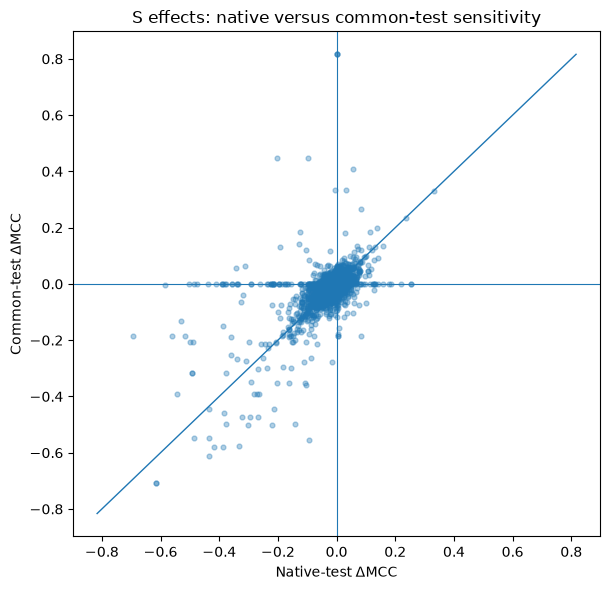

S Spearman(native Δ, common Δ) = 0.5752337852411443


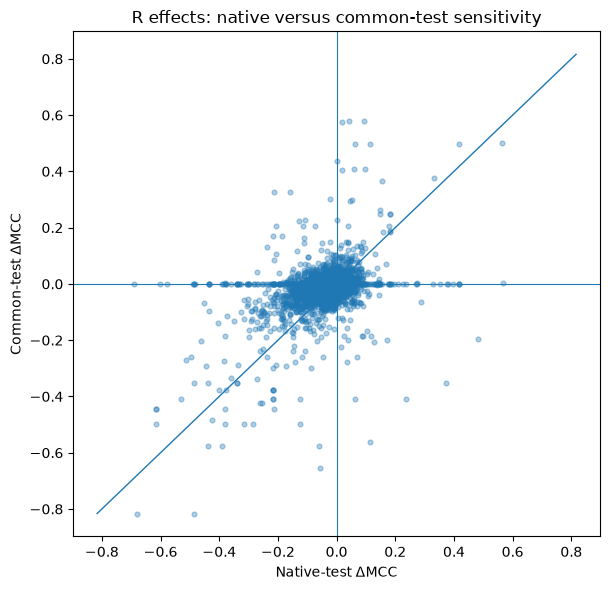

R Spearman(native Δ, common Δ) = 0.35673575923275946


In [18]:
for axis in ["S", "R"]:
    d = pairwise[
        pairwise["axis"].eq(axis)
        & pairwise["metric"].eq("mcc")
        & pairwise["native_delta"].notna()
        & pairwise["common_delta"].notna()
    ].copy()

    fig, ax = plt.subplots(figsize=(6.2, 6.0))
    ax.scatter(
        d["native_delta"],
        d["common_delta"],
        s=12,
        alpha=0.35,
    )

    lim = max(
        abs(d["native_delta"]).max(),
        abs(d["common_delta"]).max(),
    )
    ax.plot(
        [-lim, lim],
        [-lim, lim],
        linewidth=1,
    )
    ax.axhline(0, linewidth=0.8)
    ax.axvline(0, linewidth=0.8)
    ax.set_xlabel("Native-test ΔMCC")
    ax.set_ylabel("Common-test ΔMCC")
    ax.set_title(
        f"{axis} effects: native versus common-test sensitivity"
    )
    plt.tight_layout()
    plt.show()

    print(
        axis,
        "Spearman(native Δ, common Δ) =",
        d["native_delta"].corr(
            d["common_delta"],
            method="spearman",
        ),
    )


# 18. How often does common-test evaluation materially change the conclusion?


In [19]:
conclusion_change_rows = []

for axis in ["S", "R"]:
    d = pairwise[
        pairwise["axis"].eq(axis)
        & pairwise["metric"].eq("mcc")
        & pairwise["native_delta"].notna()
        & pairwise["common_delta"].notna()
    ].copy()

    conclusion_change_rows.append({
        "axis": axis,
        "n": len(d),
        "sign_agreement": d["sign_agreement"].mean(),
        "sign_flip_fraction": (
            d["native_sign"] != d["common_sign"]
        ).mean(),
        "median_abs_native": d["native_abs_effect"].median(),
        "median_abs_common": d["common_abs_effect"].median(),
        "median_abs_change_in_delta": (
            d["native_delta"] - d["common_delta"]
        ).abs().median(),
        "fraction_abs_change_gt_0_02": (
            (
                d["native_delta"] - d["common_delta"]
            ).abs() > 0.02
        ).mean(),
        "fraction_common_smaller_abs": (
            d["common_abs_effect"] < d["native_abs_effect"]
        ).mean(),
        "spearman_native_common": d["native_delta"].corr(
            d["common_delta"],
            method="spearman",
        ),
    })

conclusion_change = pd.DataFrame(conclusion_change_rows)
display(conclusion_change)


,axis,n,sign_agreement,sign_flip_fraction,median_abs_native,median_abs_common,median_abs_change_in_delta,fraction_abs_change_gt_0_02,fraction_common_smaller_abs,spearman_native_common
0,S,3360,0.684821,0.315179,0.018663,0.014653,0.014842,0.405655,0.546131,0.575234
1,R,3340,0.594611,0.405389,0.043023,0.018061,0.040772,0.733234,0.721856,0.356736


# 19. VAL-specific support guardrail


In [20]:
val_guardrail = (
    pairwise[
        pairwise["task"].eq("subtype_val")
        & pairwise["metric"].eq("mcc")
    ]
    .groupby(["axis", "contrast"])
    .agg(
        n=("common_delta", "count"),
        median_n_common=("n_common", "median"),
        median_positive_common=("n_positive_common", "median"),
        min_positive_common=("n_positive_common", "min"),
        median_min_class_count=(
            "min_class_count_common", "median"
        ),
        native_median=("native_delta", "median"),
        common_median=("common_delta", "median"),
    )
    .reset_index()
)

display(val_guardrail)


,axis,contrast,n,median_n_common,median_positive_common,min_positive_common,median_min_class_count,native_median,common_median
0,R,50→30,80,705.5,3.0,3.0,3.0,0.015435,0.0
1,R,70→30,80,705.5,4.5,3.0,4.5,-0.089619,0.0
2,R,70→50,80,1145.0,5.0,4.0,5.0,-0.133167,0.0
3,R,90→30,60,712.0,4.0,0.0,6.5,-0.044254,0.0
4,R,90→50,80,1137.0,4.5,3.0,4.5,-0.112124,0.0
5,R,90→70,80,1637.5,6.0,4.0,6.0,0.035625,0.0
6,S,50→30,80,1512.0,8.5,3.0,8.5,-0.007621,0.0
7,S,70→30,80,1504.0,7.0,3.0,7.0,-0.042328,0.0
8,S,70→50,80,1667.0,12.5,5.0,12.5,0.000000,0.0
9,S,90→30,80,1526.0,6.5,2.0,6.5,-0.035334,0.0


VAL common-test effects can be scientifically useful while still being numerically fragile.

RQ16 therefore reports their support but does not use common-test VAL behavior to override the evidence-limited interpretation established in RQ10.


# 20. Compact RQ16 evidence tables


In [21]:
rq16_evidence = (
    pairwise[
        pairwise["contrast"].eq("90→30")
        & pairwise["metric"].eq("mcc")
    ]
    .groupby(["axis", "task"])
    .agg(
        n=("common_delta", "count"),
        native_delta_median=("native_delta", "median"),
        common_delta_median=("common_delta", "median"),
        native_abs_median=("native_abs_effect", "median"),
        common_abs_median=("common_abs_effect", "median"),
        sign_agreement=(
            "sign_agreement",
            lambda x: pd.to_numeric(
                x, errors="coerce"
            ).mean(),
        ),
        common_negative_fraction=(
            "common_delta",
            lambda x: (x < 0).mean(),
        ),
        median_n_common=("n_common", "median"),
        median_common_fraction=(
            "common_fraction_of_smaller_test", "median"
        ),
        median_min_class_support=(
            "min_class_count_common", "median"
        ),
    )
    .reset_index()
)

rq16_interaction_evidence = (
    corner_mcc.groupby("task")
    .agg(
        n=("common_interaction", "count"),
        native_interaction_median=(
            "native_interaction", "median"
        ),
        common_interaction_median=(
            "common_interaction", "median"
        ),
        common_positive_fraction=(
            "common_interaction",
            lambda x: (x > 0).mean(),
        ),
        interaction_sign_agreement=(
            "interaction_sign_agreement",
            lambda x: pd.to_numeric(
                x, errors="coerce"
            ).mean(),
        ),
        median_n_common=("n_common", "median"),
        median_common_fraction=(
            "common_fraction_of_smallest_corner_test", "median"
        ),
    )
    .reset_index()
)

display(rq16_evidence)
display(rq16_interaction_evidence)


,axis,task,n,native_delta_median,common_delta_median,native_abs_median,common_abs_median,sign_agreement,common_negative_fraction,median_n_common,median_common_fraction,median_min_class_support
0,R,global_easy,80,-0.102103,-0.021692,0.102103,0.025795,0.7250,0.7250,760.0,0.283428,143.0
1,R,global_hard,80,-0.045614,-0.011627,0.045614,0.018790,0.6625,0.6500,198.5,0.271546,64.5
2,R,global_mixed,80,-0.103402,-0.016139,0.103402,0.025566,0.7375,0.7375,843.0,0.285367,136.5
3,R,multiclass_clean,80,-0.022622,0.000000,0.030760,0.025702,0.4875,0.4500,135.0,0.284211,5.5
4,R,subtype_depolymerase,80,0.018144,-0.005688,0.037814,0.028813,0.4625,0.5125,727.0,0.283431,28.0
5,R,subtype_endolysin,80,-0.142878,-0.032223,0.142878,0.034352,0.7750,0.7750,806.5,0.284480,110.0
6,R,subtype_val,60,-0.044254,0.000000,0.111745,0.059469,0.3500,0.2500,712.0,0.286461,6.5
7,S,global_easy,80,-0.017895,-0.019209,0.018622,0.019987,0.8250,0.8625,1641.5,0.301533,263.0
8,S,global_hard,80,-0.007104,-0.000081,0.012490,0.014249,0.6750,0.5000,404.0,0.302077,110.5
9,S,global_mixed,80,-0.023472,-0.014678,0.023472,0.020035,0.8000,0.8000,1708.0,0.300620,221.0


,task,n,native_interaction_median,common_interaction_median,common_positive_fraction,interaction_sign_agreement,median_n_common,median_common_fraction
0,global_easy,20,0.047088,-0.053888,0.30,0.25,68.0,0.025307
1,global_hard,20,0.021067,0.000000,0.45,0.45,28.0,0.038304
2,global_mixed,20,0.010090,-0.000826,0.35,0.45,82.0,0.027844
3,multiclass_clean,20,0.028747,0.000000,0.05,0.10,21.0,0.044492
4,subtype_depolymerase,20,0.061084,0.000000,0.25,0.20,74.0,0.028986
5,subtype_endolysin,20,0.080343,0.023874,0.65,0.60,83.0,0.029360
6,subtype_val,0,0.339206,NaN,0.00,NaN,89.0,0.035829


# 21. RQ16 synthesis questions


After execution, RQ16 should answer:

1. How much pairwise exact-sequence overlap exists across S levels at fixed R?
2. How much overlap remains across all four S levels?
3. How much overlap exists across R levels, where the biological universe itself changes?
4. Do prediction-derived native metrics reproduce Stage12A exactly?
5. Does the global `S90→S30` MCC penalty persist on common proteins?
6. Does the S penalty remain larger at R90 than at R30 on the same proteins?
7. Does the conclusion persist with AP-skill?
8. Does multiclass macro-F1 tell the same qualitative story?
9. Does the native `R90→R30` effect persist on R-common proteins?
10. Which biological tasks are most sensitive to test composition?
11. Are VAL common-test contrasts adequately supported, or extremely fragile?
12. Does representation change the amount of native/common discrepancy?
13. How often do native and common deltas have the same sign?
14. How strongly are native and common deltas correlated?
15. How often does fixing test entities change MCC delta by more than 0.02?
16. Do pairwise intersections and four-level intersections tell the same story?
17. Does the positive extreme R×S interaction from RQ4 persist on a four-corner common test?
18. Does the attenuation of the S effect under stringent R persist in the four-corner common set?
19. Are any previous R/S claims primarily driven by test composition and therefore in need of qualification?
20. Which native claims become substantially stronger because they survive exact common-entity evaluation?

RQ16 should not produce a new leaderboard.

Its purpose is to tell us **which generalization conclusions survive control of the evaluated biological entities**.


## Manuscript-level interpretation targets

If S effects persist:

> **The degradation associated with remote homology separation is not explained by changes in test-set composition alone; the same proteins become harder to classify when models are trained under stricter homology-separated regimes.**

If the R×S interaction persists:

> **The non-additive relationship between redundancy control and homology separation remains detectable when the same proteins are evaluated across the four extreme R/S conditions, supporting a genuine interaction in model generalization rather than a compositional artifact.**

If native effects attenuate strongly:

> **Part of the apparent protocol effect reflects changes in which proteins enter the evaluation set, emphasizing that native factorial deltas quantify both model generalization and population shift.**

The likely final manuscript should report native effects as the benchmark result and common-test effects as a robustness/sensitivity layer.


# 22. Export RQ16 cache tables


In [22]:
EXPORTS = {
    CACHE_DIR / "rq16_native_prediction_metric_qc.tsv":
        qc,
    CACHE_DIR / "rq16_prediction_identity_audit.tsv":
        identity_audit,
    CACHE_DIR / "rq16_common_test_overlap_audit.tsv":
        overlap_audit,
    CACHE_DIR / "rq16_pairwise_common_test_contrasts.tsv":
        pairwise,
    CACHE_DIR / "rq16_fourlevel_common_test_metrics.tsv":
        fourway_metrics,
    CACHE_DIR / "rq16_fourlevel_common_test_contrasts.tsv":
        fourway_contrasts,
    CACHE_DIR / "rq16_fourcorner_common_test_metrics.tsv":
        corner_metrics_df,
    CACHE_DIR / "rq16_fourcorner_interaction_sensitivity.tsv":
        corner_summary,
    CACHE_DIR / "rq16_native_vs_common_summary.tsv":
        conclusion_change,
    CACHE_DIR / "rq16_evidence_summary.tsv":
        rq16_evidence,
    CACHE_DIR / "rq16_interaction_evidence_summary.tsv":
        rq16_interaction_evidence,
    CACHE_DIR / "rq16_val_common_test_support.tsv":
        val_guardrail,
}

for path, frame in EXPORTS.items():
    frame.to_csv(
        path,
        sep="\t",
        index=False,
    )

print("Saved RQ16 cache tables:")
for path in EXPORTS:
    print(" ", path)


Saved RQ16 cache tables:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq16_native_prediction_metric_qc.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq16_prediction_identity_audit.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq16_common_test_overlap_audit.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq16_pairwise_common_test_contrasts.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq16_fourlevel_common_test_metrics.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq16_fourlevel_common_test_contrasts.tsv
  /home/da

## Final guardrails before freezing RQ16

- Do not replace native Stage12 results with common-test metrics.
- Native tests answer performance across the frozen evaluation population.
- Common tests answer robustness to evaluation-population composition.
- Use S common-test results as the primary sensitivity analysis.
- Treat R common-test results as secondary because R changes the available biological universe.
- Always report overlap/support when citing common-test effects.
- Keep VAL support-aware.
- Do not attach bootstrap confidence intervals here; RQ17 handles paired uncertainty.
- A surviving common-test R×S interaction is especially strong evidence.
- A disappearing interaction is equally important and must qualify RQ4.
